![](img/banner.png)
%%HTML
<script src="require.js"></script>

## Comparison of LDA and PCA 

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

* 2D projection of Iris dataset

In [1]:
%matplotlib inline

The Iris dataset represents 3 kind of Iris flowers (Setosa, Versicolour
and Virginica) with 4 attributes: sepal length, sepal width, petal length
and petal width.

Principal Component Analysis (PCA) applied to this data identifies the
combination of attributes (principal components, or directions in the
feature space) that account for the most variance in the data. Here we
plot the different samples on the 2 first principal components.

Linear Discriminant Analysis (LDA) tries to identify attributes that
account for the most variance *between classes*. In particular,
LDA, in contrast to PCA, is a supervised method, using known class labels.


explained variance ratio (first two components): [0.92461872 0.05306648]


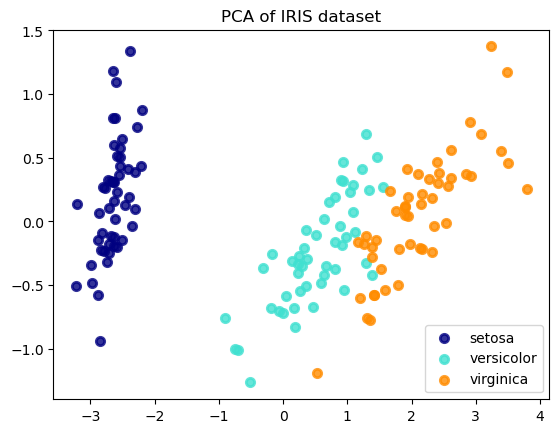

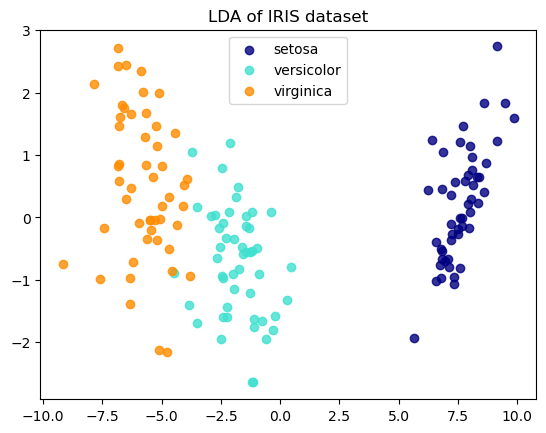

In [2]:
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

iris = datasets.load_iris()

X = iris.data
y = iris.target
target_names = iris.target_names

pca = PCA(n_components=2)
X_r = pca.fit(X).transform(X)

lda = LinearDiscriminantAnalysis(n_components=2)
X_r2 = lda.fit(X, y).transform(X)

# Percentage of variance explained for each components
print('explained variance ratio (first two components): %s'
      % str(pca.explained_variance_ratio_))

plt.figure()
colors = ['navy', 'turquoise', 'darkorange']
lw = 2

for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=.8, lw=lw,
                label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA of IRIS dataset')

plt.figure()
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X_r2[y == i, 0], X_r2[y == i, 1], alpha=.8, color=color,
                label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('LDA of IRIS dataset')

plt.show()

## From a picture to a number

The two scatter plots look convincing, but "the classes look separated" is not a measurement. Here
we compare three classifiers on the same Iris data and the same folds:

1. logistic regression on the four raw features;
2. PCA to two components, then logistic regression;
3. LDA used as the classifier --- it reduces the dimension and classifies in one step.

Two habits make this comparison honest:

* **Standardize before projecting.** PCA is driven by variance, so the attribute with the largest
  numeric spread dominates the components. LDA also assumes comparable scales.
* **Fit the projection inside the cross-validation loop.** Projecting the whole data set once and
  then cross-validating the classifier leaks the variance structure of the test fold into training.
  A `Pipeline` refits the scaler and the projection in every fold.


In [3]:
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

models = {
    "logistic regression, 4 raw features":
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "standardize + PCA(2) + logistic":
        make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=1000)),
    "standardize + LDA":
        make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    print(f"{name:42s} accuracy = {scores.mean():.3f} +/- {scores.std():.3f}")


logistic regression, 4 raw features        accuracy = 0.953 +/- 0.043
standardize + PCA(2) + logistic            accuracy = 0.913 +/- 0.060
standardize + LDA                          accuracy = 0.980 +/- 0.031


LDA wins here, and the reason is structural rather than accidental: LDA **knows the labels** and
chooses the direction that maximizes between-class scatter relative to within-class scatter. PCA
knows nothing about the classes; it keeps the directions of largest total variance, and part of
that variance is the spread *inside* each class.

That does not make PCA worse --- it makes it **unsupervised**. When the labels are missing, or the
goal is compression rather than separation, PCA is the tool.


In [4]:
Xs = StandardScaler().fit_transform(X)
pca_s = PCA(n_components=2).fit(Xs)

print("PCA on standardized features, cumulative explained variance:",
      pca_s.explained_variance_ratio_.cumsum()[-1].round(4))
print("PCA on raw features (the first figure above):               ",
      pca.explained_variance_ratio_.cumsum()[-1].round(4))

# LDA cannot exceed C-1 components: with 3 classes there are only 2 independent
# between-class directions, and both of them are used here.
lda_s = LinearDiscriminantAnalysis(n_components=2).fit(Xs, y)
print("LDA, cumulative explained variance (2 components):          ",
      lda_s.explained_variance_ratio_.cumsum()[-1].round(4))

try:
    LinearDiscriminantAnalysis(n_components=3).fit(Xs, y)
    print("3 LDA components accepted (sklearn would truncate)")
except ValueError as err:
    print("asking for 3 LDA components fails as expected:", str(err)[:110])


PCA on standardized features, cumulative explained variance: 0.9581
PCA on raw features (the first figure above):                0.9777
LDA, cumulative explained variance (2 components):           1.0
asking for 3 LDA components fails as expected: n_components cannot be larger than min(n_features, n_classes - 1).


### One direction, two criteria

Reducing to a single dimension shows the difference between the two criteria most clearly.

* PCA takes the direction of maximum variance, $\max_w w^\top S w$ with $S$ the total scatter.
  Nothing in that objective mentions the classes.
* LDA takes the direction that maximizes the *ratio* of between-class to within-class scatter,

$$J(w) = \frac{w^\top S_B w}{w^\top S_W w},$$

  which is the Fisher criterion. A direction can carry a lot of total variance and still be useless
  for classification, if that variance is the spread inside each class.

The two panels below project the same standardized data onto one dimension and report
$S_B/S_W$ --- larger is better separated. Histograms that overlap mean confusion, whatever the
accuracy of the resulting classifier.


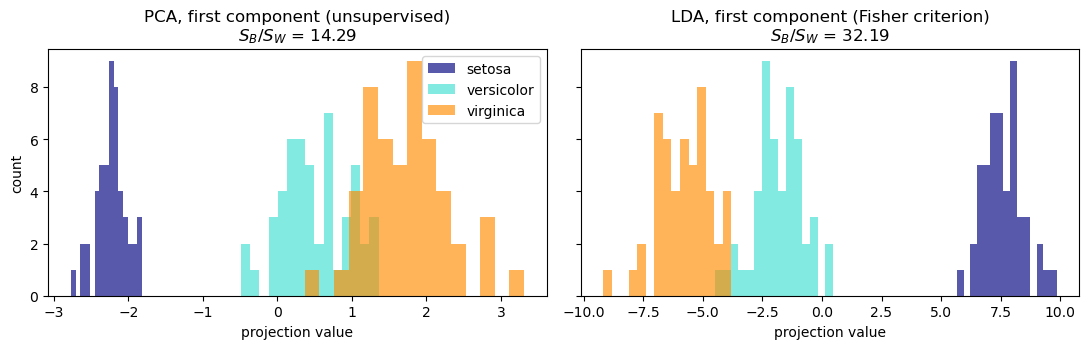

In [5]:
pca1 = PCA(n_components=1).fit_transform(Xs)
lda1 = LinearDiscriminantAnalysis(n_components=1).fit(Xs, y).transform(Xs)

def fisher_ratio(z):
    # between-class scatter over within-class scatter of a 1D projection
    z = z.ravel()
    overall = z.mean()
    sb = sum((z[y == k].mean() - overall) ** 2 * (y == k).sum() for k in np.unique(y))
    sw = sum(((z[y == k] - z[y == k].mean()) ** 2).sum() for k in np.unique(y))
    return sb / sw

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
panels = [(axes[0], pca1, "PCA, first component (unsupervised)"),
          (axes[1], lda1, "LDA, first component (Fisher criterion)")]

for ax, z, title in panels:
    for color, k, name in zip(colors, range(3), target_names):
        ax.hist(z[y == k, 0], bins=15, alpha=.65, color=color, label=name)
    ax.set_title(f"{title}\n$S_B/S_W$ = {fisher_ratio(z):.2f}")
    ax.set_xlabel("projection value")

axes[0].set_ylabel("count")
axes[0].legend()
plt.tight_layout()
plt.show()


In [6]:
# Where does the remaining error go? Cross-validated LDA predictions.
y_pred = cross_val_predict(
    make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), X, y, cv=cv)

cm = confusion_matrix(y, y_pred)
print("rows = true, columns = predicted, order:", list(target_names))
print(cm)
for k, name in enumerate(target_names):
    print(f"recall({name:12s}) = {cm[k, k] / cm[k].sum():.3f}")


rows = true, columns = predicted, order: ['setosa', 'versicolor', 'virginica']
[[50  0  0]
 [ 0 48  2]
 [ 0  1 49]]
recall(setosa      ) = 1.000
recall(versicolor  ) = 0.960
recall(virginica   ) = 0.980


### PCA or LDA?

| | PCA | LDA |
|---|---|---|
| Needs labels | no | **yes** |
| Criterion | maximize total variance | maximize $S_B / S_W$ |
| Maximum components | $\min(n, d)$ | $C - 1$ |
| Can reconstruct the data | yes | no |
| Typical use | compression, visualization, denoising | supervised reduction, visualization, cheap classifier |
| Sensitive to feature scale | yes | yes |

LDA has no reconstruction error to minimize: its directions are chosen for separation, not for
representing the data, so you cannot use LDA to compress or denoise. Conversely, PCA can easily keep
a direction that mixes the classes; that is why the PCA panel needed two components to look
convincing, while LDA was already separating well in one.


### Three things to take from this notebook

1. **Supervised or not** is the dividing line: PCA maximizes variance, LDA maximizes separation.
2. **LDA is capped at $C-1$ components.** With three classes there is no third discriminant.
3. **Standardize, and fit inside the CV loop.** The projection is part of the model, not part of
   the data. In the project, the same mistake --- computing a projection (or a window statistic) on
   all data before splitting --- is the most common way to get a beautiful and meaningless score.
